In [37]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier,RandomForestRegressor
from sklearn.metrics import accuracy_score,r2_score
import matplotlib.pyplot as plt
import os
os.chdir('E:/Machine_Learning/Cases/Wisconsin/')

In [24]:
df = pd.read_csv('BreastCancer.csv',index_col=0)
df.head()

,Clump,UniCell_Size,Uni_CellShape,MargAdh,SEpith,BareN,BChromatin,NoemN,Mitoses,Class
Code,,,,,,,,,,
61634,5,4,3,1,2,2,2,3,1,Benign
63375,9,1,2,6,4,10,7,7,2,Malignant
76389,10,4,7,2,2,8,6,1,1,Malignant
95719,6,10,10,10,8,10,7,10,7,Malignant
128059,1,1,1,1,2,5,5,1,1,Benign


In [25]:
X,y = df.drop('Class',axis = 1),df['Class']
X_train,X_test,y_train,y_test= train_test_split(X,y,test_size=0.3,random_state=26,stratify=y)
rf = RandomForestClassifier(n_estimators=25,max_features=3)
rf.fit(X_train,y_train)
y_pred = rf.predict(X_test)
accuracy_score(y_test,y_pred)

0.9619047619047619

In [29]:
m_feat=[2,3,4,5]
samples = [25,50,100]
scores = []
for m in m_feat:
    for s in samples:
        rf = RandomForestClassifier(n_estimators=s,max_features=m,random_state=26)
        rf.fit(X_train,y_train)
        y_pred = rf.predict(X_test)
        scores.append([s,m,accuracy_score(y_test,y_pred)])
df_s =pd.DataFrame(scores,columns=['n','Max_features','accuracy'])
df_s.sort_values(by= 'accuracy',ascending=False)

,n,Max_features,accuracy
0,25,2,0.966667
1,50,2,0.966667
2,100,2,0.966667
4,50,3,0.966667
11,100,5,0.966667
5,100,3,0.966667
7,50,4,0.966667
8,100,4,0.966667
10,50,5,0.966667
3,25,3,0.961905


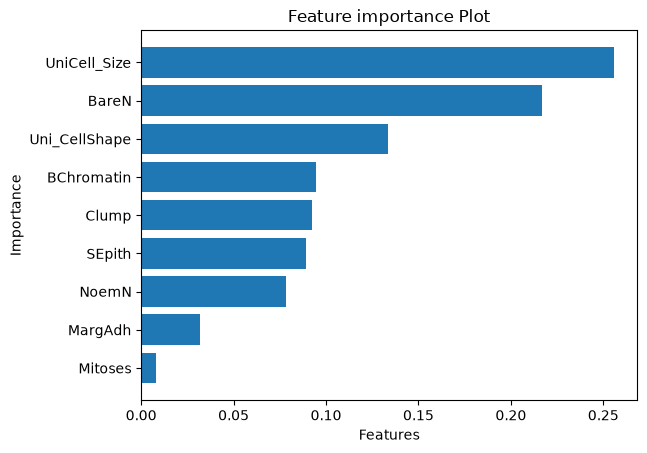

In [36]:
best_tree = RandomForestClassifier(max_features=2,n_estimators=10,random_state=26)
best_tree.fit(X,y)

df_imp = pd.DataFrame({
    'features':list(X.columns),
    'importance':best_tree.feature_importances_
})
df_imp.sort_values('importance',inplace=True)
plt.barh(df_imp['features'],df_imp['importance'])
plt.title('Feature importance Plot')
plt.xlabel('Features')
plt.ylabel('Importance')
plt.show()

In [28]:
best_tree.feature_importances_

array([0.09217681, 0.25553378, 0.1336192 , 0.03185682, 0.08911832,
       0.21686044, 0.09461224, 0.07843173, 0.00779066])

# RandomForestRegressor

In [51]:
os.chdir('E:/Machine_Learning/Cases/Concrete_Strength/')

In [52]:
df = pd.read_csv('Concrete_Data.csv')
df.head()

,Cement,Blast,Fly,Water,Superplasticizer,Coarse,Fine,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [53]:
X,y=df.drop('Strength',axis=1),df['Strength']
X_train,X_test,y_train,y_test=train_test_split(X,y,random_state=26,test_size=0.3)

In [54]:
m_feat=[2,3,4,5]
samples = [25,50,100]
scores = []
for m in m_feat:
    for s in samples:
        rf = RandomForestRegressor(n_estimators=s,max_features=m,random_state=26)
        rf.fit(X_train,y_train)
        y_pred = rf.predict(X_test)
        scores.append([s,m,r2_score(y_test,y_pred)])
df_s =pd.DataFrame(scores,columns=['n','Max_features','r2'])
df_s.sort_values(by= 'r2',ascending=False)

,n,Max_features,r2
8,100,4,0.892511
11,100,5,0.892347
4,50,3,0.889646
7,50,4,0.889587
5,100,3,0.889134
6,25,4,0.888983
10,50,5,0.888295
9,25,5,0.885371
3,25,3,0.884090
0,25,2,0.875060


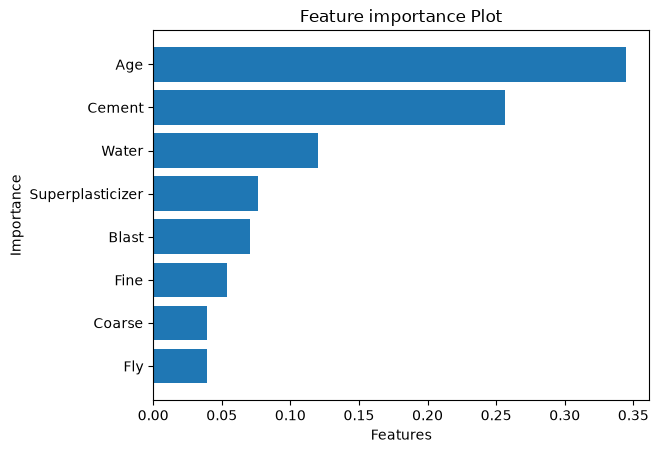

In [55]:
best_tree = RandomForestRegressor(max_features=4,n_estimators=100,random_state=26)
best_tree.fit(X,y)

df_imp = pd.DataFrame({
    'features':list(X.columns),
    'importance':best_tree.feature_importances_
})
df_imp.sort_values('importance',inplace=True)
plt.barh(df_imp['features'],df_imp['importance'])
plt.title('Feature importance Plot')
plt.xlabel('Features')
plt.ylabel('Importance')
plt.show()